In [1]:
!pip install transformers
!pip install tqdm

In [2]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from transformers import BertTokenizer, BertModel

In [3]:
train_df = pd.read_csv("/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/train.csv")
test_df = pd.read_csv("/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/test.csv")

train_df["id"] = train_df["id"].astype(str)
test_df["id"] = test_df["id"].astype(str)

print("Train shape:", train_df.shape)
train_df.head()

Train shape: (12467, 10)


,id,sentence,gloss,bvh_path,base_tokens,residual_1,residual_2,residual_3,residual_4,residual_5
0,1000648,Don't keep me on tenterhooks!,KEEP ME TENTHOOK//,dataset/1000648/1000648.bvh,379 295 376 376 376 376 376 376 133 133 376 37...,339 441 88 87 87 87 88 288 405 333 333 248 212...,406 183 8 301 476 6 169 255 452 462 66 255 463...,315 424 330 104 364 104 142 142 166 353 353 10...,64 32 15 326 466 20 229 456 71 71 71 390 20 90...,306 376 367 367 133 235 276 350 367 350 437 36...
1,1002815,"I like to be home, that way I can work on my s...",ME LIKE HOME WORK STORY FINISH//,dataset/1002815/1002815.bvh,130 276 174 174 174 174 174 174 174 50 50 50 2...,339 194 389 88 88 88 88 333 287 87 79 79 501 7...,406 406 452 202 321 321 321 321 58 356 348 75 ...,351 212 308 308 308 236 236 424 76 333 206 195...,64 125 500 222 456 153 153 498 498 498 488 177...,474 313 367 445 372 167 367 394 241 295 66 225...
2,1003115,Can I stay here tonight?,STAY HERE TONIGHT ME?,dataset/1003115/1003115.bvh,379 185 185 185 185 185 185 185 185 185 185 18...,339 441 87 87 88 88 88 288 308 88 325 483 483 ...,396 171 11 11 211 211 321 430 464 464 283 267 ...,65 449 376 191 503 503 142 166 384 143 384 348...,64 230 328 411 349 71 424 71 498 456 234 85 34...,306 201 367 6 266 406 123 71 343 428 38 404 37...
3,1003242,What a nice thing to say!,NICE THING SAY//,dataset/1003242/1003242.bvh,130 216 216 216 216 216 216 216 216 216 216 21...,339 441 333 333 333 333 333 333 333 9 9 333 17...,406 224 406 176 206 419 484 354 325 206 313 35...,315 429 433 118 17 59 348 424 424 503 348 208 ...,64 38 498 502 456 379 239 164 443 456 456 164 ...,306 71 367 448 281 241 367 241 367 469 350 241...
4,1003552,Please lock the safe.,SAFE LOCK PLEASE//,dataset/1003552/1003552.bvh,379 185 185 185 185 185 185 185 185 185 185 18...,425 314 60 60 60 456 456 456 389 87 87 325 292...,8 171 286 59 59 452 395 464 389 174 174 452 10...,62 429 86 212 503 503 503 449 449 449 311 76 4...,274 38 502 354 353 121 71 227 107 110 17 474 4...,366 288 367 448 357 167 305 241 167 167 486 24...


In [4]:
import os

motion_feature_path = "/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/Motion-Features"

# Get all available npy files
available_files = set(
    f.replace(".npy", "")
    for f in os.listdir(motion_feature_path)
)

print("Available feature files:", len(available_files))

# Filter train_df
train_df = train_df[train_df["id"].isin(available_files)].reset_index(drop=True)

print("Filtered train shape:", train_df.shape)

Available feature files: 12463
Filtered train shape: (12463, 10)


In [5]:
class MotionDataset(Dataset):
    def __init__(self, df, motion_feature_path, tokenizer, max_motion_len=500):
        self.df = df
        self.motion_feature_path = motion_feature_path
        self.tokenizer = tokenizer
        self.max_motion_len = max_motion_len

    def pad_motion(self, motion):
        T, D = motion.shape
        mask = np.ones(self.max_motion_len)

        if T > self.max_motion_len:
            motion = motion[:self.max_motion_len]
        else:
            pad = np.zeros((self.max_motion_len - T, D))
            motion = np.concatenate([motion, pad], axis=0)
            mask[T:] = 0

        return motion, mask

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        sentence = row["sentence"]
        sample_id = row["id"]

        motion_path = os.path.join(
            self.motion_feature_path,
            f"{sample_id}.npy"
        )

        motion = np.load(motion_path)
        motion, mask = self.pad_motion(motion)

        tokenized = self.tokenizer(
            sentence,
            padding="max_length",
            truncation=True,
            max_length=40,
            return_tensors="pt"
        )

        return {
            "input_ids": tokenized["input_ids"].squeeze(0),
            "attention_mask": tokenized["attention_mask"].squeeze(0),
            "motion": torch.tensor(motion, dtype=torch.float32),
            "motion_mask": torch.tensor(mask, dtype=torch.float32)
        }

In [6]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

train_dataset = MotionDataset(
    train_df,
    motion_feature_path="/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/Motion-Features",
    tokenizer=tokenizer
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

print("Dataset ready.")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Dataset ready.


In [7]:
train_dataset = MotionDataset(
    train_df,
    motion_feature_path=motion_feature_path,
    tokenizer=tokenizer
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

print("Dataset rebuilt safely.")

Dataset rebuilt safely.


In [8]:
sample = train_dataset[0]
motion = sample["motion"].numpy()
mask = sample["motion_mask"].numpy()

print("Motion shape:", motion.shape)

Motion shape: (500, 668)


In [9]:
print("Feature 0 Stats:")
print("Min:", motion[:, 0].min())
print("Max:", motion[:, 0].max())
print("Mean:", motion[:, 0].mean())

Feature 0 Stats:
Min: 0.0
Max: 0.0
Mean: 0.0


In [10]:
variances = motion.var(axis=0)
top_feature = np.argmax(variances)

print("Most dynamic feature index:", top_feature)

Most dynamic feature index: 380


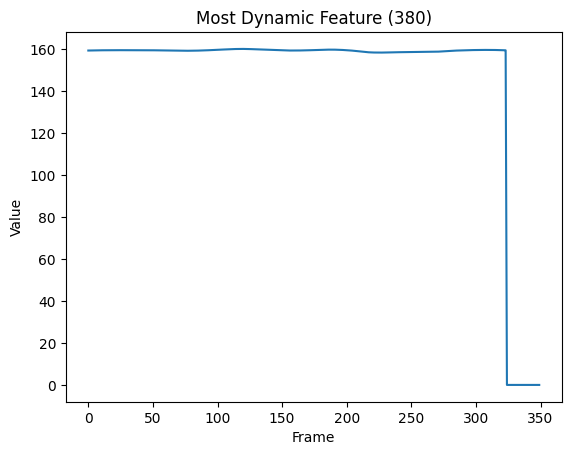

In [11]:
plt.figure()
plt.plot(motion[:350, top_feature])
plt.title(f"Most Dynamic Feature ({top_feature})")
plt.xlabel("Frame")
plt.ylabel("Value")
plt.show()

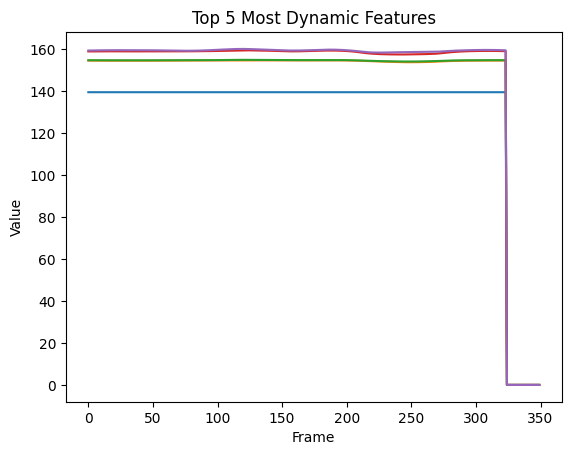

In [12]:
top5 = np.argsort(variances)[-5:]

plt.figure()
for idx in top5:
    plt.plot(motion[:350, idx])

plt.title("Top 5 Most Dynamic Features")
plt.xlabel("Frame")
plt.ylabel("Value")
plt.show()

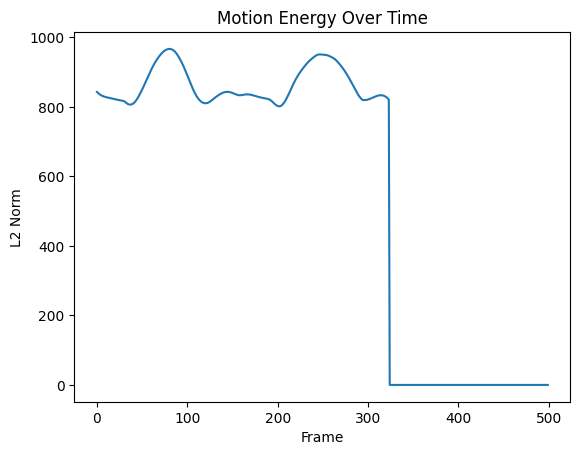

In [13]:
motion_energy = np.linalg.norm(motion, axis=1)

plt.figure()
plt.plot(motion_energy)
plt.title("Motion Energy Over Time")
plt.xlabel("Frame")
plt.ylabel("L2 Norm")
plt.show()

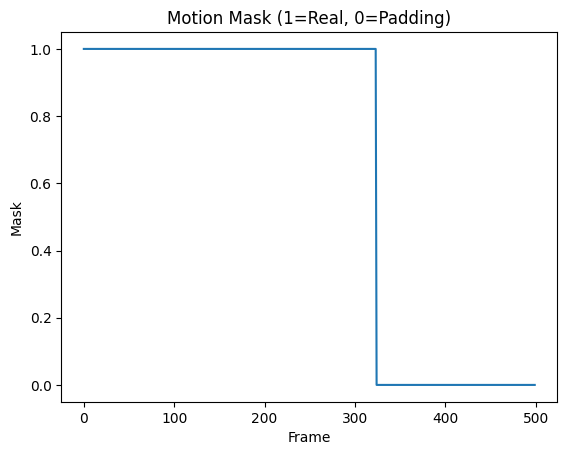

In [14]:
plt.figure()
plt.plot(mask)
plt.title("Motion Mask (1=Real, 0=Padding)")
plt.xlabel("Frame")
plt.ylabel("Mask")
plt.show()

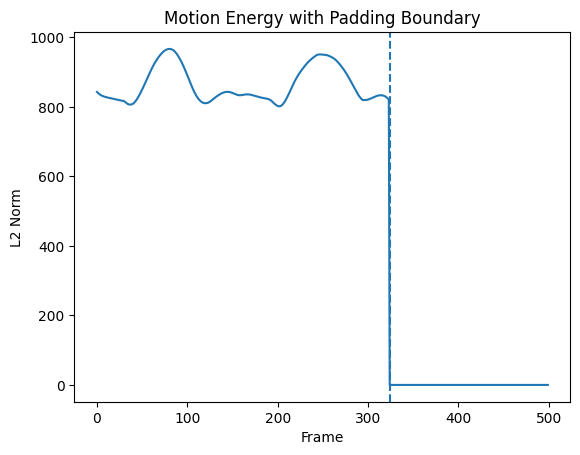

Real motion length: 324


In [15]:
real_length = int(mask.sum())

plt.figure()
plt.plot(motion_energy)
plt.axvline(real_length, linestyle='--')
plt.title("Motion Energy with Padding Boundary")
plt.xlabel("Frame")
plt.ylabel("L2 Norm")
plt.show()

print("Real motion length:", real_length)

In [16]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-np.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [17]:
class Text2Motion(nn.Module):
    def __init__(self, motion_dim=668, hidden=512):
        super().__init__()

        self.text_encoder = BertModel.from_pretrained("bert-base-uncased")
        self.text_proj = nn.Linear(768, hidden)

        self.motion_proj = nn.Linear(motion_dim, hidden)
        self.pos_enc = PositionalEncoding(hidden)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden,
            nhead=8,
            batch_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=4
        )

        self.output_layer = nn.Linear(hidden, motion_dim)

    def forward(self, input_ids, attention_mask, motion):

        text_out = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        memory = self.text_proj(text_out.last_hidden_state)

        tgt = self.motion_proj(motion)
        tgt = self.pos_enc(tgt)

        decoded = self.decoder(tgt=tgt, memory=memory)

        output = self.output_layer(decoded)

        return output

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Text2Motion().to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [19]:
epochs = 5
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        motion = batch["motion"].to(device)
        mask = batch["motion_mask"].to(device)

        optimizer.zero_grad()

        output = model(input_ids, attention_mask, motion)

        loss = ((output - motion) ** 2)
        loss = loss.mean(dim=2)
        loss = (loss * mask).sum() / mask.sum()

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    loss_history.append(epoch_loss)

    print(f"Epoch {epoch+1} Loss: {epoch_loss}")

100%|██████████| 1558/1558 [12:59<00:00,  2.00it/s]


Epoch 1 Loss: 467.237091417031


100%|██████████| 1558/1558 [08:23<00:00,  3.09it/s]


Epoch 2 Loss: 30.627628524128983


100%|██████████| 1558/1558 [07:55<00:00,  3.27it/s]


Epoch 3 Loss: 8.142068503603856


100%|██████████| 1558/1558 [07:35<00:00,  3.42it/s]


Epoch 4 Loss: 2.3324356905838646


100%|██████████| 1558/1558 [07:34<00:00,  3.43it/s]

Epoch 5 Loss: 0.7129517980063375


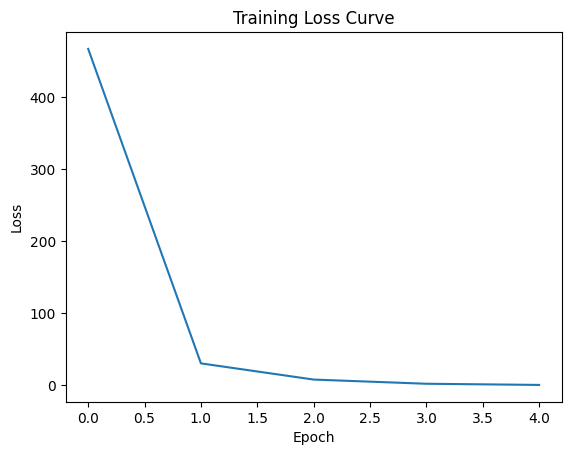

In [20]:
plt.figure()
plt.plot(loss_history)
plt.title("Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

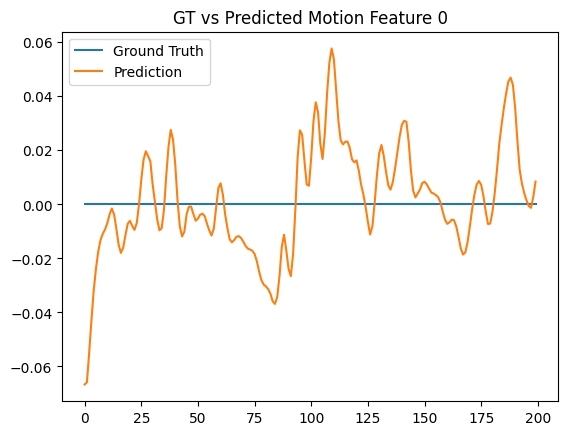

In [21]:
model.eval()

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
motion = batch["motion"].to(device)

with torch.no_grad():
    pred = model(input_ids, attention_mask, motion)

gt = motion[0].cpu().numpy()
pred = pred[0].cpu().numpy()

plt.figure()
plt.plot(gt[:200, 0], label="Ground Truth")
plt.plot(pred[:200, 0], label="Prediction")
plt.legend()
plt.title("GT vs Predicted Motion Feature 0")
plt.show()

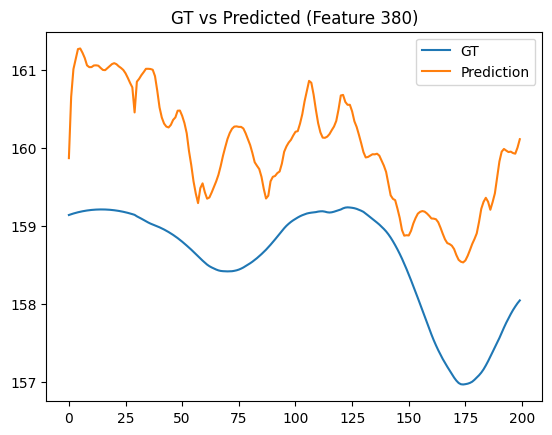

In [22]:
variances = gt.var(axis=0)
top_feature = np.argmax(variances)

plt.figure()
plt.plot(gt[:200, top_feature], label="GT")
plt.plot(pred[:200, top_feature], label="Prediction")
plt.legend()
plt.title(f"GT vs Predicted (Feature {top_feature})")
plt.show()

In [23]:
BASE_PATH = "/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language"

test_df = pd.read_csv(f"{BASE_PATH}/test.csv")
sample_sub = pd.read_csv(f"{BASE_PATH}/sample_submission.csv")

print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_sub.shape)

sample_sub.head()


Test shape: (3000, 3)
Sample submission shape: (5, 7)


,id,base_tokens,residual_1,residual_2,residual_3,residual_4,residual_5
0,6420249,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
1,6420682,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
2,6425789,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
3,6425858,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
4,6427530,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0


In [24]:
sample_sub = pd.read_csv("/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/sample_submission.csv")

for col in sample_sub.columns:
    if col != "id":
        print(col, "token count:",
              len(sample_sub.iloc[0][col].split()))


base_tokens token count: 10
residual_1 token count: 10
residual_2 token count: 10
residual_3 token count: 10
residual_4 token count: 10
residual_5 token count: 10


In [25]:
# Copy sample submission structure
submission = sample_sub.copy()

# Fill prediction column with dummy values (safe baseline)

if "motion" in submission.columns:
    submission["motion"] = "0"

if "layered_motion_tokens" in submission.columns:
    submission["layered_motion_tokens"] = "0"

print("Submission preview:")
submission.head()

Submission preview:


,id,base_tokens,residual_1,residual_2,residual_3,residual_4,residual_5
0,6420249,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
1,6420682,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
2,6425789,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
3,6425858,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0
4,6427530,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0,0 0 0 0 0 0 0 0 0 0


In [26]:
sample_sub = pd.read_csv("/kaggle/input/motion-s-hierarchical-text-to-motion-generation-for-sign-language/sample_submission.csv")

submission = sample_sub.copy()

# Replace all token strings with same-length zeros
for col in submission.columns:
    if col != "id":
        token_count = len(submission.iloc[0][col].split())
        zero_string = " ".join(["0"] * token_count)
        submission[col] = zero_string

submission.to_csv("submission.csv", index=False)

print("Fixed submission.csv created.")


Fixed submission.csv created.


In [27]:
submission.to_csv("submission.csv", index=False)

print("submission.csv created successfully.")


submission.csv created successfully.


In [28]:
print(os.listdir("/kaggle/working"))


['submission.csv', '__notebook__.ipynb']
